In [13]:
import numpy as np
import os
import pandas as pd

def load_image_data_from_csv(csv_file, line_index, dataset_root):
    """
    Reads the image file path from the CSV at the given line_index, 
    loads the corresponding .npy image file, and returns the image data.

    Parameters:
    - csv_file: Path to the CSV file containing metadata.
    - line_index: The index of the line to retrieve from the CSV.
    - dataset_root: The root directory where the .npy files are located.

    Returns:
    - image_data: The loaded image data as a NumPy array.
    """
    # Ensure the CSV file exists
    if not os.path.exists(csv_file):
        raise FileNotFoundError(f"CSV file not found: {csv_file}")

    # Load the CSV file
    df = pd.read_csv(csv_file)

    # Check if line_index is valid
    if line_index < 0 or line_index >= len(df):
        raise IndexError(f"Line index {line_index} is out of range. CSV has {len(df)} lines.")

    # Get the file path for the image from the CSV (relative path)
    relative_path = df.iloc[line_index]['file_paths']
    image_path = os.path.join(dataset_root, relative_path)

    # Check if the .npy file exists
    if not os.path.exists(image_path):
        raise FileNotFoundError(f"Image file not found: {image_path}")

    # Load the image data from the .npy file
    image_data = np.load(image_path)

    return image_data

# Example usage:
# csv_file = '/path/to/your/csv_file.csv'
# line_index = 5  # Change this to the desired line number
# dataset_root = '/path/to/your/dataset_root'

# image_data = load_image_data_from_csv(csv_file, line_index, dataset_root)
# print(image_data.shape)  # To check the shape of the image data


In [14]:
csv_file = '/mnt/Research/arsalan/wsu_grid_rs_grp_mljet/ml-jet-ext/pTHat50-250_eCM5020_agg/metadata/c0005_alpha0p20_q_1p0_unfolded_events.csv'
line_index = 5  # The index of the image you want to load
dataset_root = '/mnt/Research/arsalan/wsu_grid_rs_grp_mljet/ml-jet-ext/pTHat50-250_eCM5020_agg'

# Load the image data
image_data = load_image_data_from_csv(csv_file, line_index, dataset_root)

# Print the shape of the loaded image data
print(image_data.shape)
import numpy as np
non_zero_tupples = np.nonzero(image_data)
image_data[non_zero_tupples]

(32, 32)


array([  0.318166,   5.52628 ,   1.44154 ,   0.821679,  12.2445  ,
       104.61209 ,   1.45183 ], dtype=float32)

In [15]:
image_data[16,11]

np.float32(0.0)

In [18]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import os

def plot_image_from_csv_line(
    csv_file,
    line_index,
    dataset_root,
    phi_range=(-np.pi, np.pi),
    eta_range=(-2.8, 2.8),
    # phi_range=(-0.4, 0.4),
    # eta_range=(-0.4, 0.4),
    cmap="jet",
):
    """
    Reads a specific line from a CSV file, loads the corresponding .npy image,
    and plots it with physical phi/eta axes.

    Parameters
    ----------
    csv_file : str
        Path to the per-config CSV file.
    line_index : int
        Zero-based row index (0 -> first event).
    dataset_root : str
        Root directory where the .npy event files are located.
    phi_range : tuple
        (phi_min, phi_max), default (0, 2π).
    eta_range : tuple
        (eta_min, eta_max), default (-2.8, 2.8).
    """
    if not os.path.exists(csv_file):
        raise FileNotFoundError(f"CSV file not found: {csv_file}")

    df = pd.read_csv(csv_file)
    if line_index < 0 or line_index >= len(df):
        raise IndexError(f"line_index {line_index} out of bounds (0..{len(df)-1})")

    row = df.iloc[line_index]
    relative_path = row["file_paths"]
    event_path = os.path.join(dataset_root, relative_path)

    if not os.path.exists(event_path):
        raise FileNotFoundError(f"Event .npy file not found: {event_path}")

    image_data = np.load(event_path)

    print(f"Config: alpha={row['alpha']}, q0={row['q0']}, seed={row['seed']}")
    print(f"File:   {relative_path}")
    print(f"Shape:  {image_data.shape}, min={image_data.min():.4g}, max={image_data.max():.4g}")

    phi_min, phi_max = phi_range
    eta_min, eta_max = eta_range

    plt.figure(figsize=(6, 5))
    # transpose so x=phi, y=eta
    plt.imshow(
        image_data.T,
        origin="lower",
        extent=[phi_min, phi_max, eta_min, eta_max],
        aspect="auto",
        cmap=cmap,
        interpolation="nearest",
    )
    cbar = plt.colorbar()
    cbar.set_label(r"$\sum p_T$ in bin (GeV)")

    plt.title(f"phi–eta pT map\nalpha={row['alpha']}, q0={row['q0']}, seed={row['seed']}, R=0.4 CorrectedRotationVariant")
    plt.xlabel(r"$\phi$")
    plt.ylabel(r"$\eta$")
    plt.tight_layout()
    plt.show()


Config: alpha=0.2, q0=1.0, seed=0
File:   c0005_alpha0p20_q_1p0_unfolded/seed_000/event_0000500.npy
Shape:  (32, 32), min=0, max=76.3


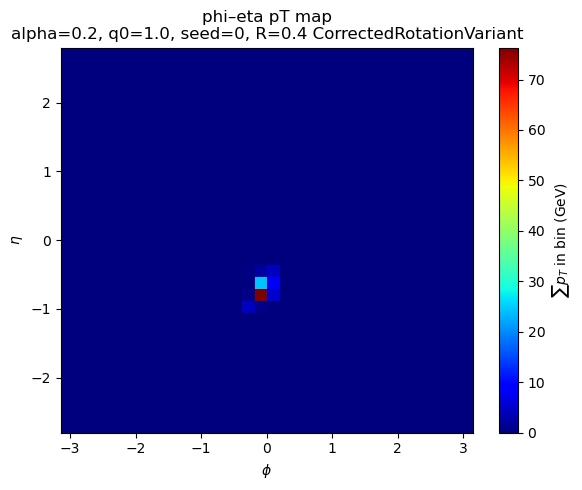

Config: alpha=0.2, q0=1.0, seed=0
File:   c0005_alpha0p20_q_1p0_unfolded/seed_000/event_0000501.npy
Shape:  (32, 32), min=0, max=98.67


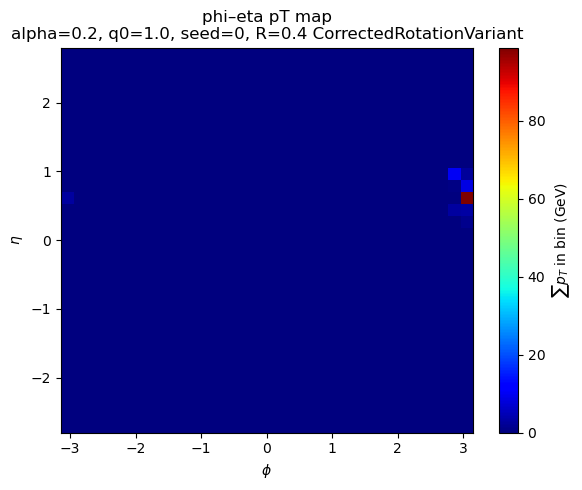

Config: alpha=0.2, q0=1.0, seed=0
File:   c0005_alpha0p20_q_1p0_unfolded/seed_000/event_0000502.npy
Shape:  (32, 32), min=0, max=64.49


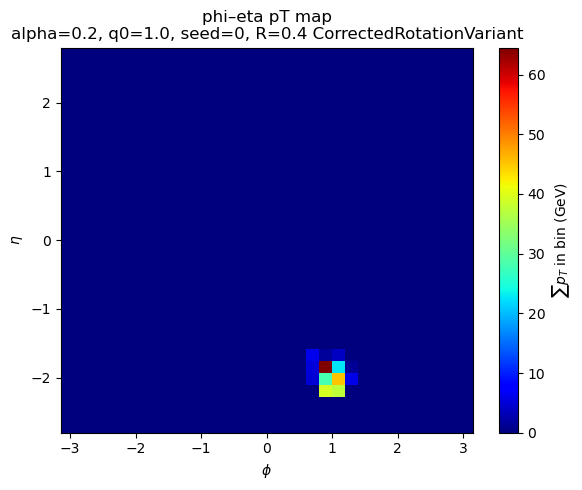

Config: alpha=0.2, q0=1.0, seed=0
File:   c0005_alpha0p20_q_1p0_unfolded/seed_000/event_0000503.npy
Shape:  (32, 32), min=0, max=93.61


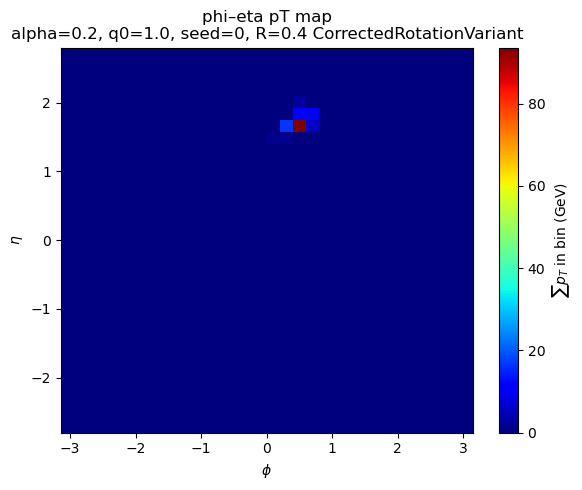

Config: alpha=0.2, q0=1.0, seed=0
File:   c0005_alpha0p20_q_1p0_unfolded/seed_000/event_0000504.npy
Shape:  (32, 32), min=0, max=60.46


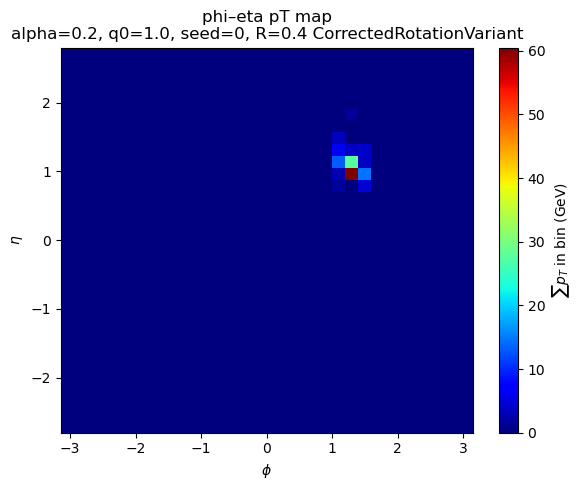

In [19]:
csv_file = "/mnt/Research/arsalan/wsu_grid_rs_grp_mljet/ml-jet-ext/pTHat50-250_eCM5020_agg/metadata/c0005_alpha0p20_q_1p0_unfolded_events.csv"
dataset_root = "/mnt/Research/arsalan/wsu_grid_rs_grp_mljet/ml-jet-ext/pTHat50-250_eCM5020_agg"
for line_index in range(500,505):
    plot_image_from_csv_line(csv_file, line_index, dataset_root)

Config: alpha=0.2, q0=1.0, seed=0
File:   c0005_alpha0p20_q_1p0_unfolded/seed_000/event_0000500.npy
Shape:  (32, 32), min=0, max=43.67


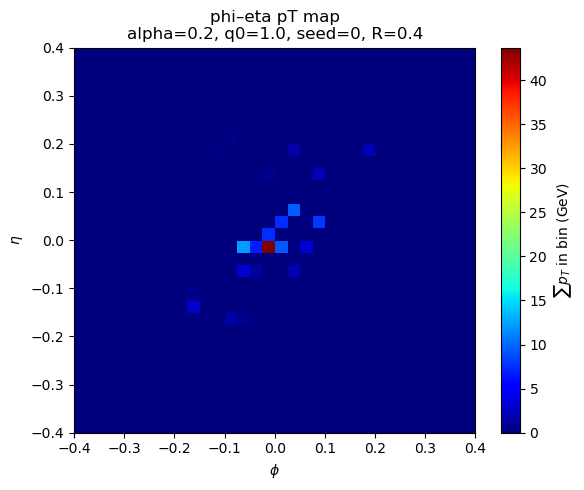

Config: alpha=0.2, q0=1.0, seed=0
File:   c0005_alpha0p20_q_1p0_unfolded/seed_000/event_0000501.npy
Shape:  (32, 32), min=0, max=41.21


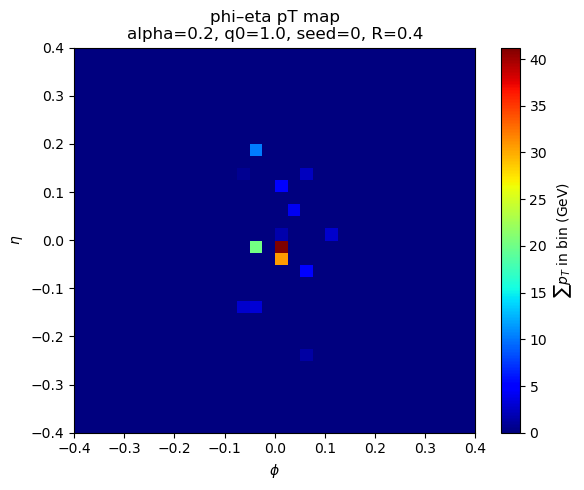

Config: alpha=0.2, q0=1.0, seed=0
File:   c0005_alpha0p20_q_1p0_unfolded/seed_000/event_0000502.npy
Shape:  (32, 32), min=0, max=52.56


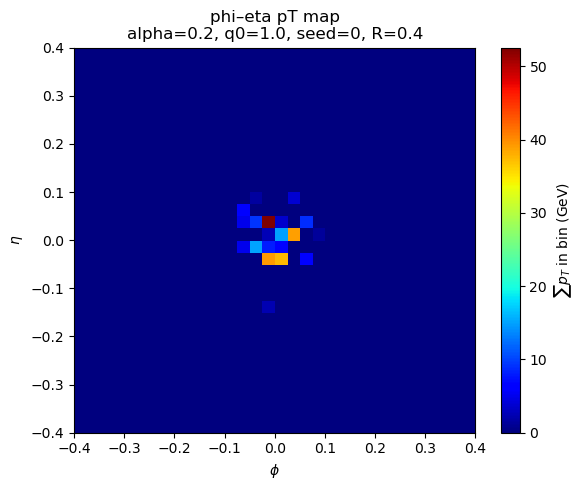

Config: alpha=0.2, q0=1.0, seed=0
File:   c0005_alpha0p20_q_1p0_unfolded/seed_000/event_0000503.npy
Shape:  (32, 32), min=0, max=93.61


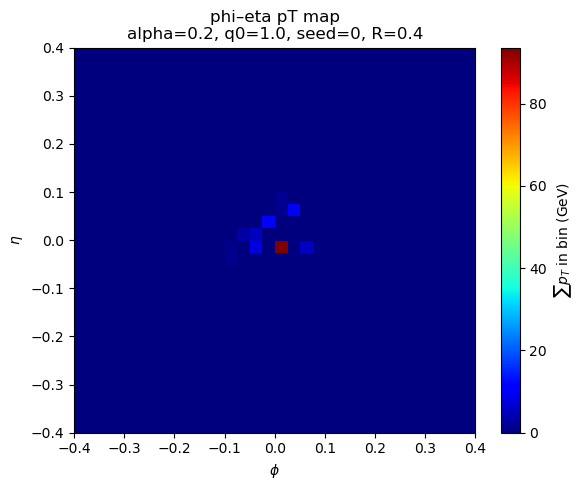

Config: alpha=0.2, q0=1.0, seed=0
File:   c0005_alpha0p20_q_1p0_unfolded/seed_000/event_0000504.npy
Shape:  (32, 32), min=0, max=28.82


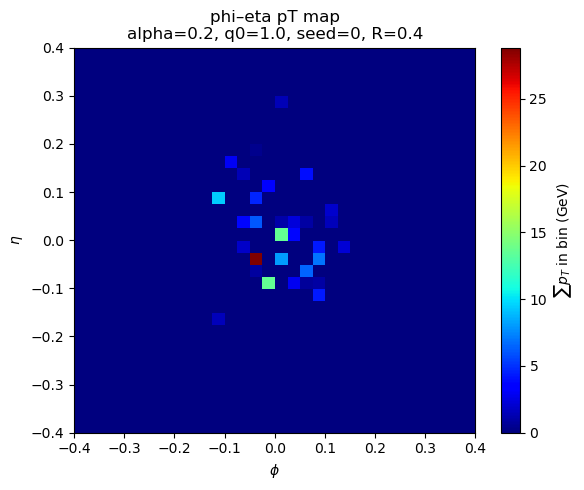

In [55]:
csv_file = "/mnt/Research/arsalan/wsu_grid_rs_grp_mljet/ml-jet-ext/pTHat50-250_eCM5020_agg/metadata/c0005_alpha0p20_q_1p0_unfolded_events.csv"
dataset_root = "/mnt/Research/arsalan/wsu_grid_rs_grp_mljet/ml-jet-ext/pTHat50-250_eCM5020_agg"
for line_index in range(500,505):
    plot_image_from_csv_line(csv_file, line_index, dataset_root)

Config: alpha=0.2, q0=1.0, seed=0
File:   c0005_alpha0p20_q_1p0_unfolded/seed_000/event_0000500.npy
Shape:  (32, 32), min=0, max=410.5


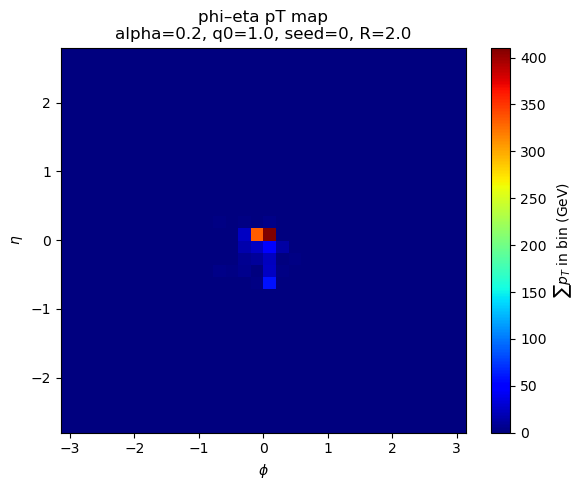

Config: alpha=0.2, q0=1.0, seed=0
File:   c0005_alpha0p20_q_1p0_unfolded/seed_000/event_0000501.npy
Shape:  (32, 32), min=0, max=185.4


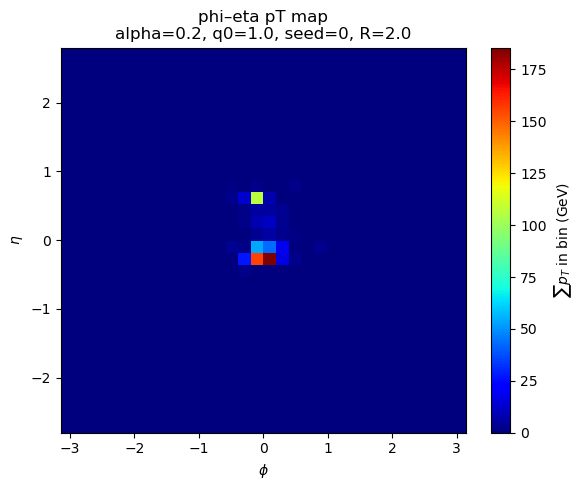

Config: alpha=0.2, q0=1.0, seed=0
File:   c0005_alpha0p20_q_1p0_unfolded/seed_000/event_0000502.npy
Shape:  (32, 32), min=0, max=197.7


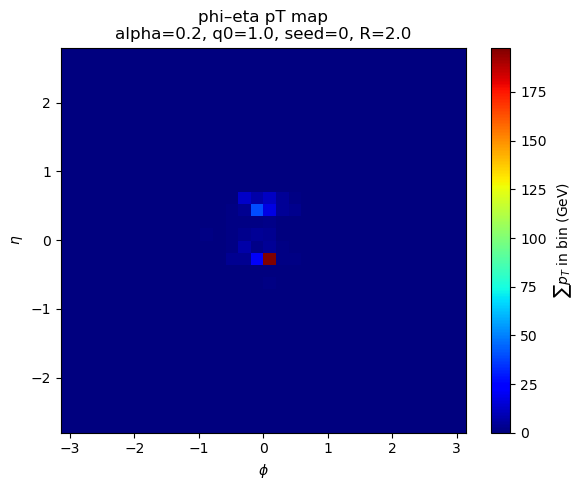

Config: alpha=0.2, q0=1.0, seed=0
File:   c0005_alpha0p20_q_1p0_unfolded/seed_000/event_0000503.npy
Shape:  (32, 32), min=0, max=910


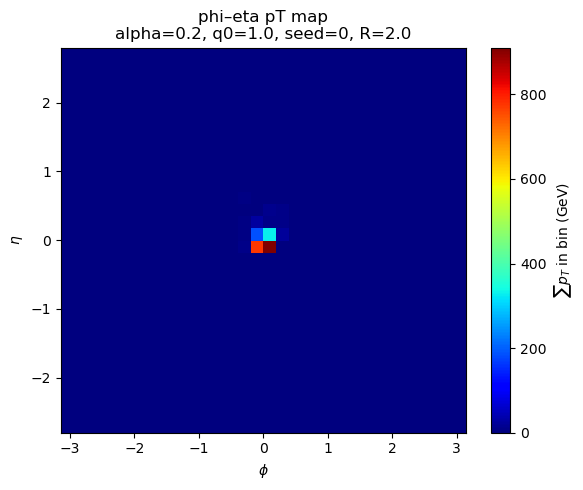

Config: alpha=0.2, q0=1.0, seed=0
File:   c0005_alpha0p20_q_1p0_unfolded/seed_000/event_0000504.npy
Shape:  (32, 32), min=0, max=30.8


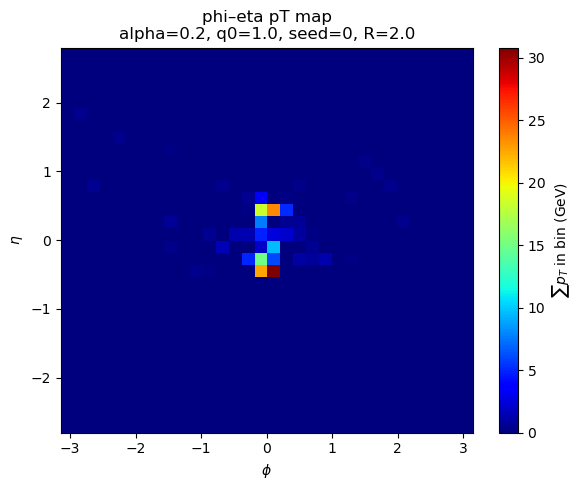

In [35]:
csv_file = "/mnt/Research/arsalan/wsu_grid_rs_grp_mljet/ml-jet-ext/pTHat50-250_eCM5020_agg/metadata/c0005_alpha0p20_q_1p0_unfolded_events.csv"
dataset_root = "/mnt/Research/arsalan/wsu_grid_rs_grp_mljet/ml-jet-ext/pTHat50-250_eCM5020_agg"
for line_index in range(500,505):
    plot_image_from_csv_line(csv_file, line_index, dataset_root)

Config: alpha=0.2, q0=1.0, seed=0
File:   c0005_alpha0p20_q_1p0_unfolded/seed_000/event_0000000.npy
Shape:  (32, 32), min=0, max=28.19


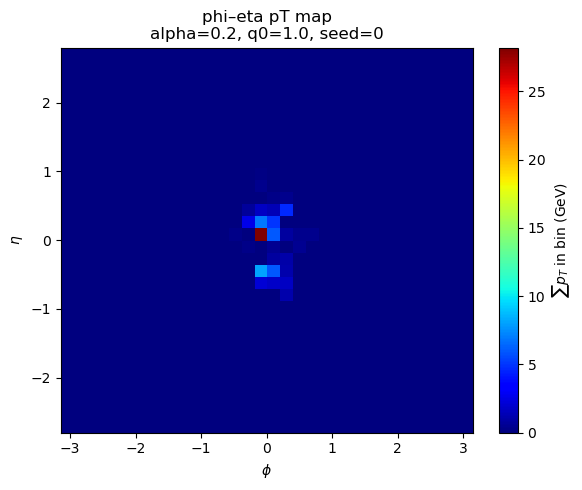

Config: alpha=0.2, q0=1.0, seed=0
File:   c0005_alpha0p20_q_1p0_unfolded/seed_000/event_0000001.npy
Shape:  (32, 32), min=0, max=100.1


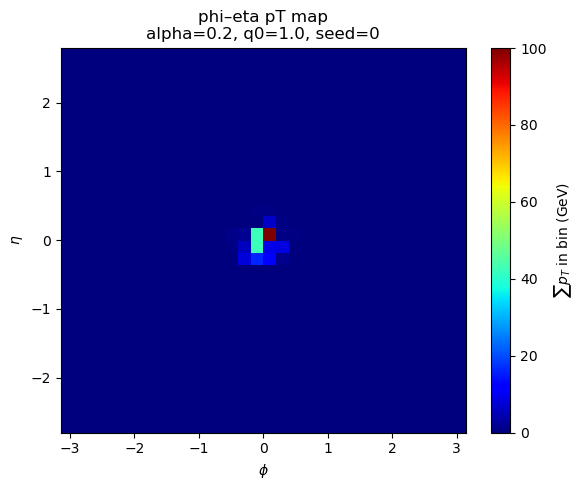

Config: alpha=0.2, q0=1.0, seed=0
File:   c0005_alpha0p20_q_1p0_unfolded/seed_000/event_0000002.npy
Shape:  (32, 32), min=0, max=121


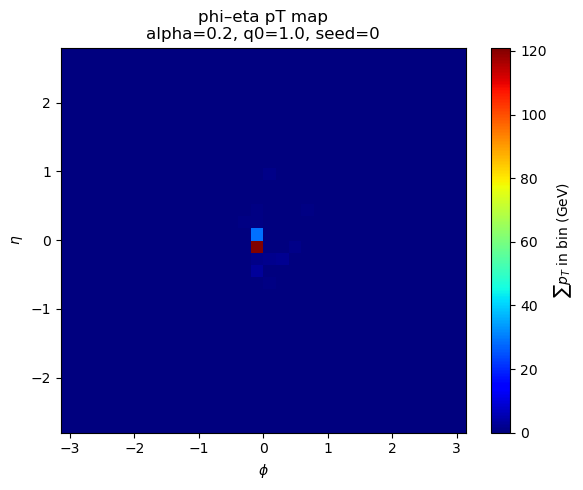

Config: alpha=0.2, q0=1.0, seed=0
File:   c0005_alpha0p20_q_1p0_unfolded/seed_000/event_0000003.npy
Shape:  (32, 32), min=0, max=313.8


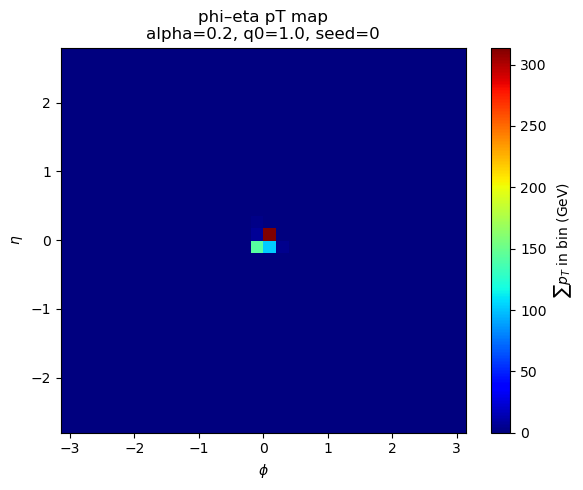

Config: alpha=0.2, q0=1.0, seed=0
File:   c0005_alpha0p20_q_1p0_unfolded/seed_000/event_0000004.npy
Shape:  (32, 32), min=0, max=63.05


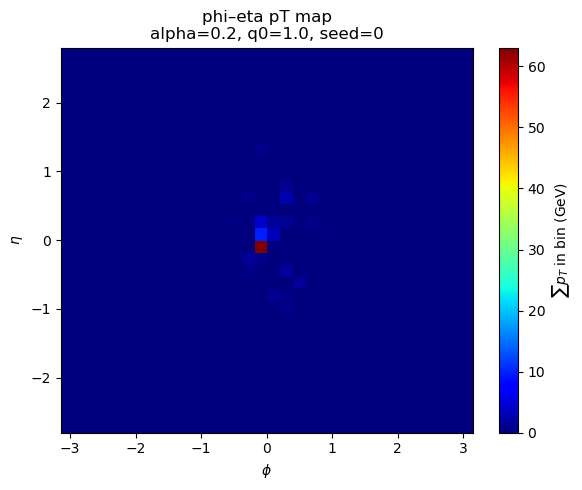

Config: alpha=0.2, q0=1.0, seed=0
File:   c0005_alpha0p20_q_1p0_unfolded/seed_000/event_0000005.npy
Shape:  (32, 32), min=0, max=247.3


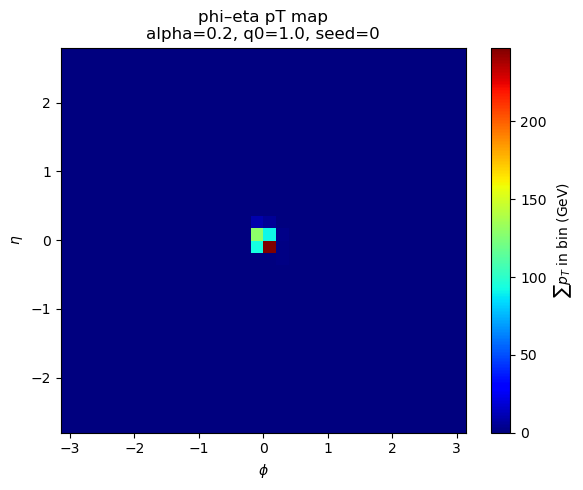

Config: alpha=0.2, q0=1.0, seed=0
File:   c0005_alpha0p20_q_1p0_unfolded/seed_000/event_0000006.npy
Shape:  (32, 32), min=0, max=108.7


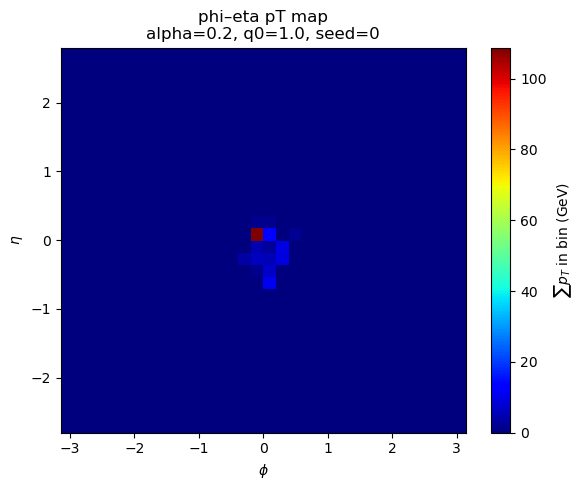

Config: alpha=0.2, q0=1.0, seed=0
File:   c0005_alpha0p20_q_1p0_unfolded/seed_000/event_0000007.npy
Shape:  (32, 32), min=0, max=54.67


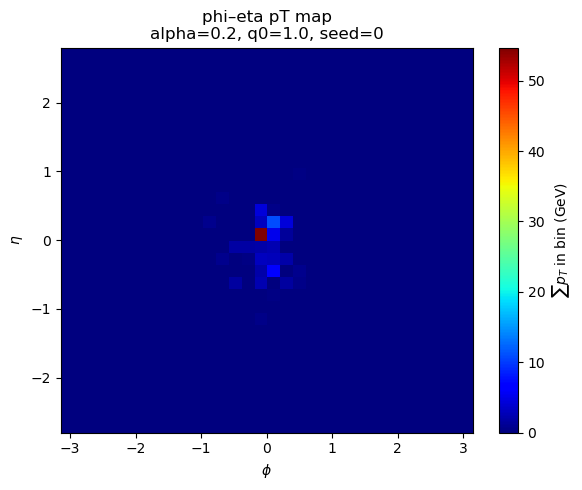

Config: alpha=0.2, q0=1.0, seed=0
File:   c0005_alpha0p20_q_1p0_unfolded/seed_000/event_0000008.npy
Shape:  (32, 32), min=0, max=87.16


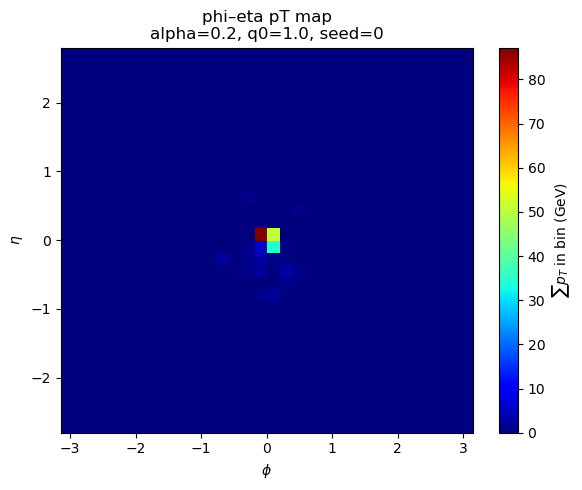

Config: alpha=0.2, q0=1.0, seed=0
File:   c0005_alpha0p20_q_1p0_unfolded/seed_000/event_0000009.npy
Shape:  (32, 32), min=0, max=239


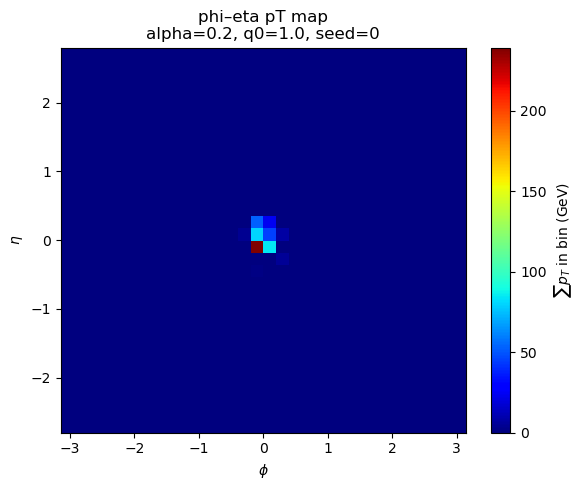

In [31]:
csv_file = "/mnt/Research/arsalan/wsu_grid_rs_grp_mljet/ml-jet-ext/pTHat50-250_eCM5020_agg/metadata/c0005_alpha0p20_q_1p0_unfolded_events.csv"
dataset_root = "/mnt/Research/arsalan/wsu_grid_rs_grp_mljet/ml-jet-ext/pTHat50-250_eCM5020_agg"
for line_index in range(10):
    plot_image_from_csv_line(csv_file, line_index, dataset_root)

In [5]:
import os
import numpy as np
import pandas as pd

def show_image_array_from_csv_line(
    csv_file,
    line_index,
    dataset_root,
    precision=3,
    threshold=2000,
    linewidth=120,
):
    """
    Load one event from CSV metadata and print its 32x32 array.

    Parameters
    ----------
    csv_file : str
        Path to per-config CSV (or the global events_index.csv).
        Must have a 'file_paths' column.
    line_index : int
        Zero-based row index (0 = first event).
    dataset_root : str
        Root directory where .npy files live (file_paths is relative to this).
    precision : int
        Number of decimal digits when printing.
    threshold : int
        Total elements before numpy starts summarizing (dots in the middle).
    linewidth : int
        Characters per line for printing.
    """
    if not os.path.exists(csv_file):
        raise FileNotFoundError(f"CSV file not found: {csv_file}")

    df = pd.read_csv(csv_file)
    if line_index < 0 or line_index >= len(df):
        raise IndexError(f"line_index {line_index} out of bounds (0..{len(df)-1})")

    row = df.iloc[line_index]
    relative_path = row["file_paths"]
    event_path = os.path.join(dataset_root, relative_path)

    if not os.path.exists(event_path):
        raise FileNotFoundError(f"Event .npy file not found: {event_path}")

    image = np.load(event_path)

    print(f"Config: alpha={row['alpha']}, q0={row['q0']}, seed={row['seed']}")
    print(f"File:   {relative_path}")
    print(f"Shape:  {image.shape}\n")

    # Print the full 32x32 array (or as much as fits) nicely
    with np.printoptions(precision=precision, suppress=True,
                         threshold=threshold, linewidth=linewidth):
        print(image)


In [20]:
csv_file = "/mnt/Research/arsalan/wsu_grid_rs_grp_mljet/ml-jet-ext/pTHat50-250_eCM5020_agg/metadata/c0005_alpha0p20_q_1p0_unfolded_events.csv"
dataset_root = "/mnt/Research/arsalan/wsu_grid_rs_grp_mljet/ml-jet-ext/pTHat50-250_eCM5020_agg"
line_index = 0

show_image_array_from_csv_line(csv_file, line_index, dataset_root)


Config: alpha=0.2, q0=1.0, seed=0
File:   c0005_alpha0p20_q_1p0_unfolded/seed_000/event_0000000.npy
Shape:  (32, 32)

[[ 0.     0.     0.     0.     0.     0.     0.     0.     0.     0.     0.     0.     0.     0.     0.     0.
   0.     0.     0.     0.     0.     0.     0.     0.     0.     0.     0.     0.     0.     0.     0.     0.   ]
 [ 0.     0.     0.     0.     0.     0.     0.     0.     0.     0.     0.     0.     0.     0.     0.     0.
   0.     0.     0.     0.     0.     0.     0.     0.     0.     0.     0.     0.     0.     0.     0.     0.   ]
 [ 0.     0.     0.     0.     0.     0.     0.     0.     0.     0.     0.     0.     0.     0.     0.     0.
   0.     0.     0.     0.     0.     0.     0.     0.     0.     0.     0.     0.     0.     0.     0.     0.   ]
 [ 0.     0.     0.     0.     0.     0.     0.     0.     0.     0.     0.     0.     0.     0.     0.     0.
   0.     0.     0.     0.     0.     0.     0.     0.     0.     0.     0.     0.     0.    

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def aggregate_and_plot_events(
    csv_file,
    dataset_root,
    start_index=0,
    num_events=500,
    phi_range=(-np.pi, np.pi),
    eta_range=(-2.8, 2.8),
    # phi_range=(-0.5, 0.5),
    # eta_range=(-0.5, 0.5),
    cmap="jet",
):
    """
    Aggregate `num_events` event images into a single 32x32 image and show it.

    Parameters
    ----------
    csv_file : str
        Path to the per-config CSV (or global events_index.csv).
        Must contain a 'file_paths' column.
    dataset_root : str
        Root directory where .npy event files live.
    start_index : int
        0-based starting row in the CSV (events are taken contiguously).
    num_events : int
        Number of events to aggregate (e.g., 500).
    phi_range : (float, float)
        Range of phi used in the histogram (default [0, 2π]).
    eta_range : (float, float)
        Range of eta used in the histogram (default [-2.8, 2.8]).
    cmap : str
        Matplotlib colormap for plotting.
    """
    if not os.path.exists(csv_file):
        raise FileNotFoundError(f"CSV file not found: {csv_file}")

    df = pd.read_csv(csv_file)
    if start_index < 0 or start_index >= len(df):
        raise IndexError(f"start_index {start_index} out of bounds (0..{len[df]-1})")

    end_index = min(start_index + num_events, len(df))
    selected = df.iloc[start_index:end_index]

    if len(selected) == 0:
        raise ValueError("No events selected for aggregation.")

    agg_image = None

    for i, (_, row) in enumerate(selected.iterrows(), start=1):
        rel_path = row["file_paths"]
        event_path = os.path.join(dataset_root, rel_path)

        if not os.path.exists(event_path):
            raise FileNotFoundError(f"Event .npy file not found: {event_path}")

        img = np.load(event_path).astype(np.float32)

         # --- per-image normalization by its max ---
        max_val = img.max()
        if max_val > 0:
            img = img / max_val
        else:
            # Completely empty image; keep as zeros
            img = np.zeros_like(img, dtype=np.float32)

        if agg_image is None:
            agg_image = np.zeros_like(img, dtype=np.float32)

        agg_image += img

    print(f"Aggregated {len(selected)} events "
          f"(rows {start_index}..{end_index-1}) into one image.")
    
    # --- compute mean image per pixel ---
    mean_image = agg_image / float(len(selected))
    
    
    print(f"Sum image shape:  {agg_image.shape}, min={agg_image.min():.4g}, max={agg_image.max():.4g}")
    print(f"Mean image shape: {mean_image.shape}, min={mean_image.min():.4g}, max={mean_image.max():.4g}")


    # Plot aggregated image
    phi_min, phi_max = phi_range
    eta_min, eta_max = eta_range

    plt.figure(figsize=(6, 5))
    plt.imshow(
        mean_image.T,
        origin="lower",
        extent=[phi_min, phi_max, eta_min, eta_max],
        aspect="auto",
        cmap=cmap,
        interpolation="nearest",
    )
    cbar = plt.colorbar()
    cbar.set_label(r"Normalized Aggregated $\sum p_T$ in bin")

    plt.title(
        f"Aggregated phi–eta pT map\n"
        f"{len(selected)} events from {os.path.basename(csv_file)}"
    )
    plt.xlabel(r"$\phi$")
    plt.ylabel(r"$\eta$")
    plt.tight_layout()
    plt.show()

    return mean_image  # in case you want to save or reuse it


Aggregated 500 events (rows 10..509) into one image.
Sum image shape:  (32, 32), min=0, max=4.359
Mean image shape: (32, 32), min=0, max=0.008718


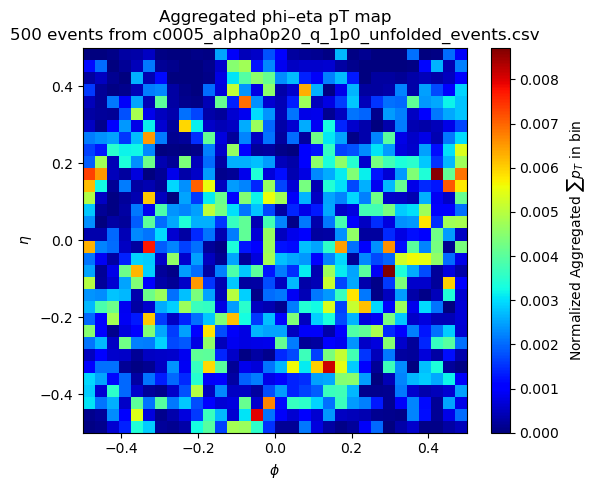

Aggregated 500 events (rows 10..509) into one image.
Sum image shape:  (32, 32), min=0, max=4.359
Mean image shape: (32, 32), min=0, max=0.008718


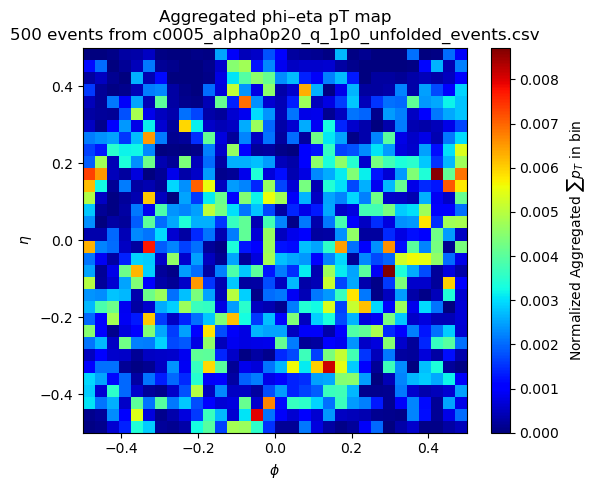

Aggregated 500 events (rows 10..509) into one image.
Sum image shape:  (32, 32), min=0, max=4.359
Mean image shape: (32, 32), min=0, max=0.008718


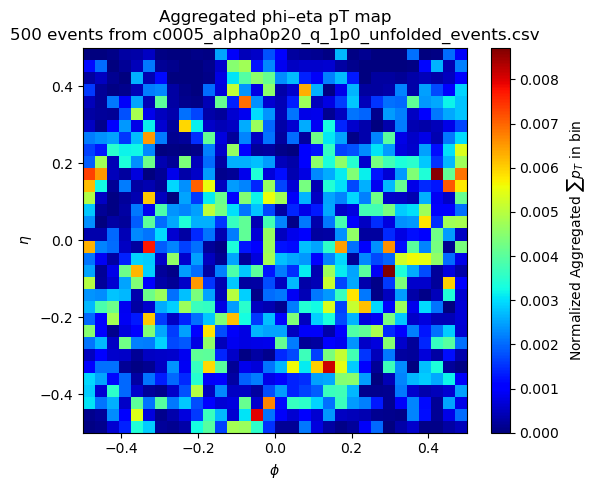

Aggregated 500 events (rows 10..509) into one image.
Sum image shape:  (32, 32), min=0, max=4.359
Mean image shape: (32, 32), min=0, max=0.008718


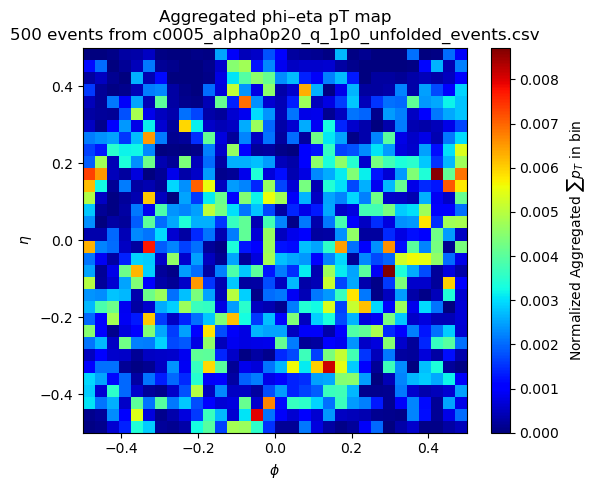

Aggregated 500 events (rows 10..509) into one image.
Sum image shape:  (32, 32), min=0, max=4.359
Mean image shape: (32, 32), min=0, max=0.008718


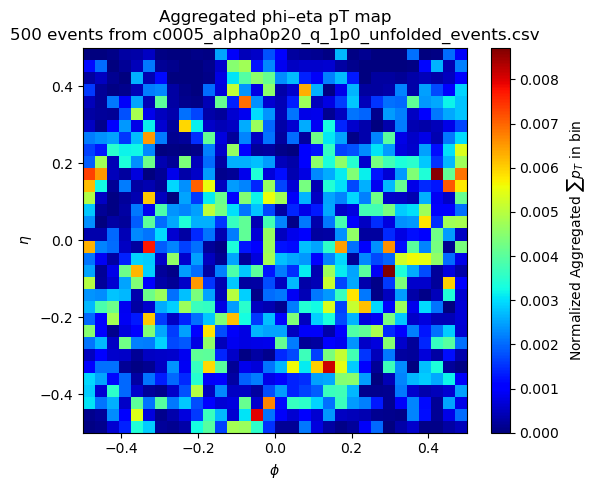

In [22]:
csv_file = "/mnt/Research/arsalan/wsu_grid_rs_grp_mljet/ml-jet-ext/pTHat50-250_eCM5020_agg/metadata/c0005_alpha0p20_q_1p0_unfolded_events.csv"
dataset_root = "/mnt/Research/arsalan/wsu_grid_rs_grp_mljet/ml-jet-ext/pTHat50-250_eCM5020_agg"

for start_idx in range(0, 1000, 200):
        agg_image = aggregate_and_plot_events(
            csv_file=csv_file,
            dataset_root=dataset_root,
            start_index=10,
            num_events=500,
        )

Aggregated 500 events (rows 10..509) into one image.
Sum image shape:  (32, 32), min=0, max=179.6
Mean image shape: (32, 32), min=0, max=0.3592


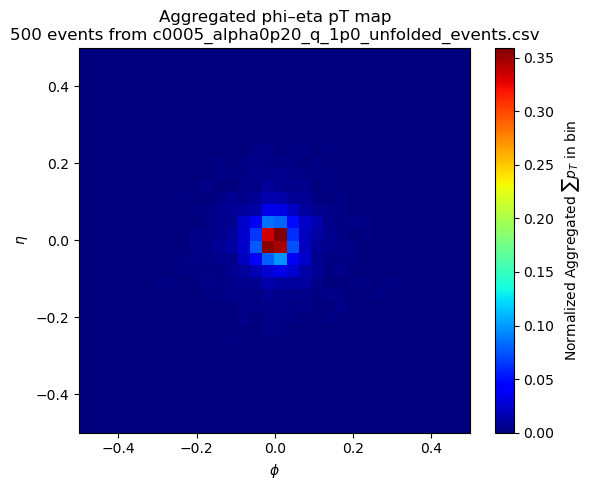

Aggregated 500 events (rows 10..509) into one image.
Sum image shape:  (32, 32), min=0, max=179.6
Mean image shape: (32, 32), min=0, max=0.3592


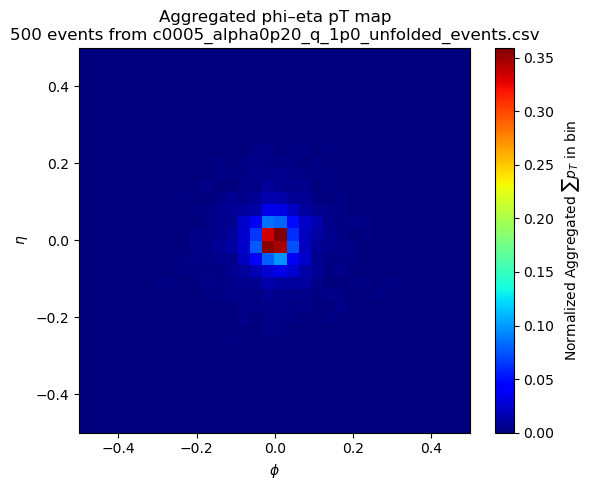

Aggregated 500 events (rows 10..509) into one image.
Sum image shape:  (32, 32), min=0, max=179.6
Mean image shape: (32, 32), min=0, max=0.3592


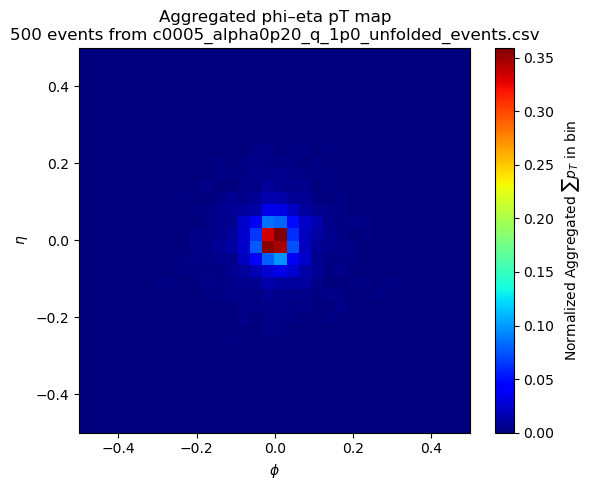

Aggregated 500 events (rows 10..509) into one image.
Sum image shape:  (32, 32), min=0, max=179.6
Mean image shape: (32, 32), min=0, max=0.3592


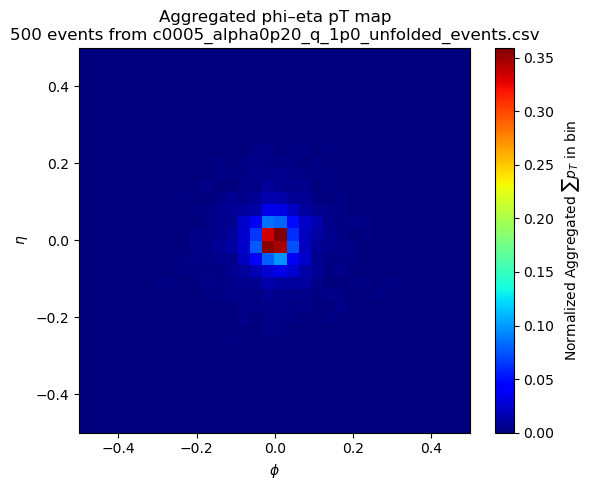

Aggregated 500 events (rows 10..509) into one image.
Sum image shape:  (32, 32), min=0, max=179.6
Mean image shape: (32, 32), min=0, max=0.3592


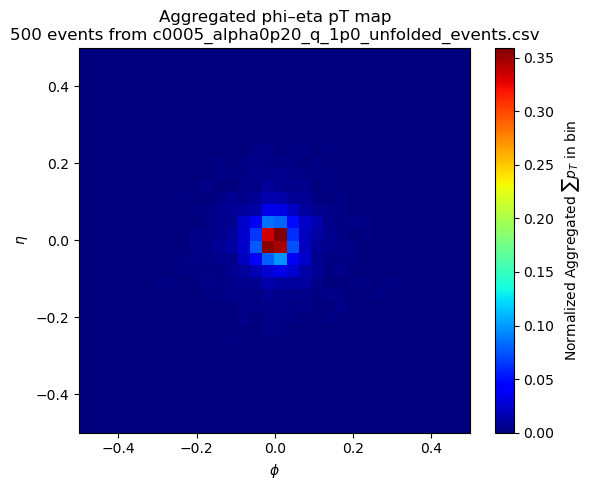

In [51]:
csv_file = "/mnt/Research/arsalan/wsu_grid_rs_grp_mljet/ml-jet-ext/pTHat50-250_eCM5020_agg/metadata/c0005_alpha0p20_q_1p0_unfolded_events.csv"
dataset_root = "/mnt/Research/arsalan/wsu_grid_rs_grp_mljet/ml-jet-ext/pTHat50-250_eCM5020_agg"

for start_idx in range(0, 1000, 200):
        agg_image = aggregate_and_plot_events(
            csv_file=csv_file,
            dataset_root=dataset_root,
            start_index=10,
            num_events=500,
        )


In [ ]:
csv_file = "/mnt/Research/arsalan/wsu_grid_rs_grp_mljet/ml-jet-ext/pTHat50-250_eCM5020_agg/metadata/c0005_alpha0p20_q_1p0_unfolded_events.csv"
dataset_root = "/mnt/Research/arsalan/wsu_grid_rs_grp_mljet/ml-jet-ext/pTHat50-250_eCM5020_agg"

agg_image = aggregate_and_plot_events(
    csv_file=csv_file,
    dataset_root=dataset_root,
    start_index=0,
    num_events=500,
)